In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    r"C:\Users\Sinchan\Downloads\AI_Customer_Intelligence\notebooks\customer_feature_engineered.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (93358, 19)


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Average_Spending_Per_Order,Customer_Value_Category,Purchase_Intensity,Spending_Category,Customer_Value_Score,Loyalty_Category,Customer_Risk_Category,Customer_Engagement_Score,Purchase_Behaviour,Recency_Category
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3,8,Loyal Customers,141.90,Medium Value,Low,Medium Value,141.90,Medium Loyalty,Low Risk,0.892857,Low Engagement Buyers,Moderate
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1,5,At Risk,27.19,Low Value,Low,Low Value,27.19,Low Loyalty,High Risk,0.869565,Low Engagement Buyers,Moderate
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4,At Risk,86.22,Low Value,Low,Low Value,86.22,Low Loyalty,High Risk,0.186220,Low Engagement Buyers,Inactive
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4,At Risk,43.62,Low Value,Low,Low Value,43.62,Low Loyalty,High Risk,0.311526,Low Engagement Buyers,Inactive
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7,Potential Customers,196.89,Medium Value,Low,Medium Value,196.89,Medium Loyalty,Medium Risk,0.347222,Low Engagement Buyers,Inactive


In [2]:
import shap

# Select the same features used in the churn model
features = [
    "Frequency",
    "Monetary",
    "Average_Spending_Per_Order",
    "Purchase_Intensity",
    "Spending_Category"
]

X = df[features].copy()

# Convert categorical features into numerical columns
X = pd.get_dummies(
    X,
    columns=["Purchase_Intensity", "Spending_Category"],
    drop_first=True
)

print("Feature Shape:", X.shape)
print("Feature Columns:", X.columns.tolist())

Feature Shape: (93358, 7)
Feature Columns: ['Frequency', 'Monetary', 'Average_Spending_Per_Order', 'Purchase_Intensity_Low', 'Purchase_Intensity_Medium', 'Spending_Category_Low Value', 'Spending_Category_Medium Value']


In [3]:
import os

model_path = r"C:\Users\Sinchan\Downloads\AI_Customer_Intelligence\models"

print(os.listdir(model_path))

[]


In [4]:
# Create churn target
df["Churn"] = np.where(df["Recency"] > 180, 1, 0)

# Check target distribution
print(df["Churn"].value_counts())

Churn
1    55006
0    38352
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = X
y = df["Churn"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (74686, 7)
Testing Data: (18672, 7)


In [6]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [7]:
from sklearn.metrics import accuracy_score, roc_auc_score

# Make predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))

Model Accuracy: 74.33 %
ROC-AUC Score: 0.7925


In [8]:
# Select 100 customers
X_sample = X_test.sample(
    n=100,
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_sample)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


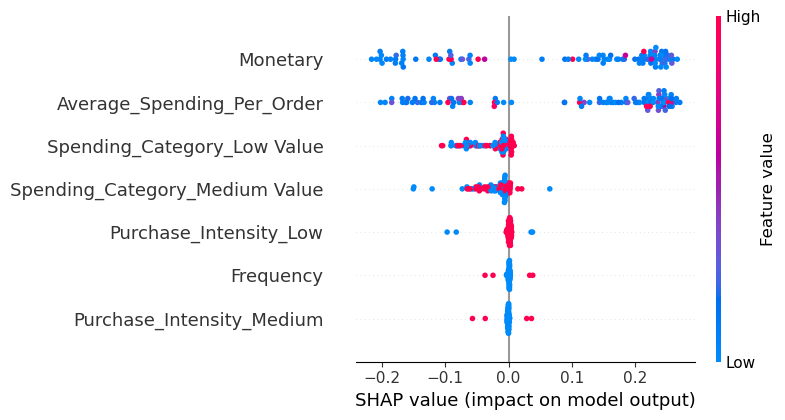

In [9]:
# SHAP summary plot
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample
)

In [10]:
# Calculate mean absolute SHAP values
shap_importance = np.abs(shap_values[:, :, 1]).mean(axis=0)

# Create feature importance dataframe
importance_df = pd.DataFrame({
    "Feature": X_sample.columns,
    "SHAP Importance": shap_importance
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="SHAP Importance",
    ascending=False
)

print(importance_df)

                          Feature  SHAP Importance
1                        Monetary         0.173849
2      Average_Spending_Per_Order         0.170620
5     Spending_Category_Low Value         0.029817
6  Spending_Category_Medium Value         0.023112
3          Purchase_Intensity_Low         0.004453
0                       Frequency         0.002445
4       Purchase_Intensity_Medium         0.002320


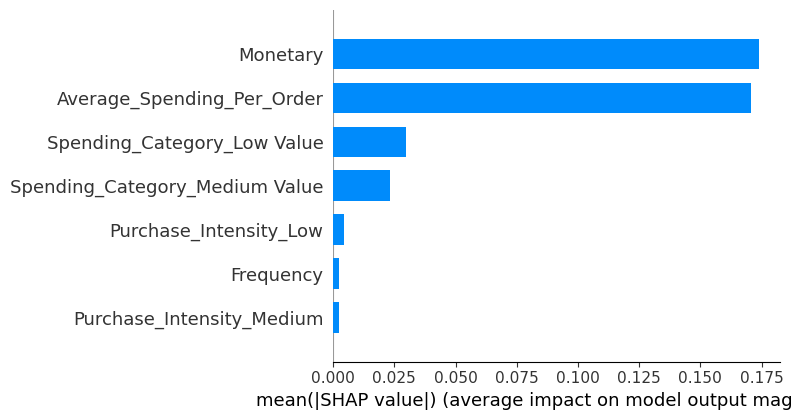

In [11]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_sample,
    plot_type="bar"
)

In [12]:
# Save SHAP feature importance
importance_df.to_csv(
    r"C:\Users\Sinchan\Downloads\AI_Customer_Intelligence\shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully!")

SHAP feature importance saved successfully!


In [13]:
!pip install ollama streamlit pandas

In [14]:
import ollama

response = ollama.chat(
    model="qwen2.5:1.5b",
    messages=[
        {
            "role": "user",
            "content": "What is customer segmentation? Explain simply."
        }
    ]
)

print(response["message"]["content"])

Customer segmentation is a method used in market research and customer management to group customers based on common characteristics or behaviors. This process allows companies to better understand their target audience and tailor their products, services, and marketing efforts to meet the specific needs of each group.

Here's a simple explanation:

1. **Understanding the Group**: Identify the primary characteristics of the customer segments, such as age, income level, lifestyle, or buying habits.

2. **Classifying Customers**: Divide the entire customer base into distinct groups based on these characteristics. Each group is unique, and customers within the same group share similar characteristics.

3. **Tailoring Strategies**: Develop tailored marketing and product strategies for each group. This ensures that the company can better serve and satisfy the needs of each group effectively.

4. **Monitoring and Adjusting**: Keep track of how well the strategies are working for each group a